# 과제1 - 202435119 한여원
## MMSE·수면·활동량을 이용한 Dem 이진 분류

AI Hub 「128.치매 고위험군 라이프로그」의 원천 데이터와 라벨 데이터를 연결한다.
대상은 사람 단위이며 Dem=1, CN/MCI=0이다. 수면·활동 피쳐 추가 효과를 MMSE 단독, 생활패턴 단독, 결합 모델로 비교한다.

항목: 데이터 선정 → 전처리 → 두 알고리즘 Pipeline → 성능지표 및 모델별 그래프 → 실제/예측 비교 → 모델 저장·재로딩·웹 시연. 

**데이터는 따로 다운받아야 합니다.** 

다운로드하기: https://aihub.or.kr/aihubdata/data/view.do?srchOptnCnd=OPTNCND001&currMenu=115&topMenu=100&searchKeyword=%EC%B9%98%EB%A7%A4&aihubDataSe=data&dataSetSn=226

파일에서 가정하는 위치는 다음과 같습니다.

*machine-learning-programming/data/128.치매 고위험군 라이프로그*

## 0. 실습 환경 준비
위에서 아래로 전체 실행한다. 설치된 패키지는 업그레이드하지 않는다. 원본 data 폴더와 assignment 폴더가 같은 상위 폴더에 있으면 경로가 자동으로 연결된다.

In [1]:
# 설치된 패키지를 매 실행마다 업그레이드하지 않는다.
import importlib.util
import subprocess
import sys
packages = {'numpy': 'numpy', 'pandas': 'pandas', 'matplotlib': 'matplotlib',
            'seaborn': 'seaborn', 'sklearn': 'scikit-learn', 'joblib': 'joblib', 'flask': 'flask'}
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', *missing])
print('필요한 패키지가 준비되었습니다.')

필요한 패키지가 준비되었습니다.


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display

from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay, roc_auc_score)

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False
RANDOM_STATE = 42
from sklearn.base import clone
from sklearn.metrics import make_scorer, balanced_accuracy_score
from sklearn.model_selection import RepeatedStratifiedKFold
import sklearn
print('Python:', __import__('sys').version.split()[0], 'sklearn:', sklearn.__version__)


Python: 3.13.14 sklearn: 1.9.1


## 1. 데이터 읽기와 구조 확인
원천 MMSE는 1인 1행, 활동·수면은 1인 여러 기록이다. 정답은 `3.인지기능` 라벨 파일에서만 읽는다. 이메일은 병합과 사람 중복 검사에만 쓰며 피쳐로 넣지 않는다.
원천에 포함된 진단명·진단 순번·검사 번호·합계 점수는 입력에서 제외한다.

In [4]:
PROJECT = Path.cwd().parent if Path.cwd().name == 'assignment1' else Path.cwd()
if not (PROJECT / 'data/128.치매 고위험군 라이프로그').exists():
    PROJECT = Path('D:/hanyeowon/가천대학교/기계학습프로그래밍')
DATA_ROOT = PROJECT / 'data/128.치매 고위험군 라이프로그/01.데이터'
OUTPUT_DIR = PROJECT / 'assignment1/라이프로그결합_output'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
raw = {}
for split, directory, prefix in [('train','1.Training','train'),('val','2.Validation','val')]:
    base = DATA_ROOT / directory
    label_file = 'training_label.csv' if split == 'train' else 'val_label.csv'
    labels = pd.read_csv(base / '라벨링데이터/3.인지기능' / label_file).set_index('SAMPLE_EMAIL')
    mmse = pd.read_csv(base / '원천데이터/3.인지기능' / f'{prefix}_mmse.csv').set_index('SAMPLE_EMAIL')
    activity = pd.read_csv(base / '원천데이터/1.걸음걸이' / f'{prefix}_activity.csv').set_index('EMAIL')
    sleep = pd.read_csv(base / '원천데이터/2.수면' / f'{prefix}_sleep.csv').set_index('EMAIL')
    assert labels.index.is_unique and mmse.index.is_unique
    assert labels.DIAG_NM.isin(['CN','MCI','Dem']).all()
    for df in [mmse, activity, sleep]:
        assert set(df.index) == set(labels.index)
    raw[split] = dict(labels=labels, mmse=mmse, activity=activity, sleep=sleep)
assert set(raw['train']['labels'].index).isdisjoint(raw['val']['labels'].index)
display(pd.DataFrame({s: d['labels'].DIAG_NM.value_counts() for s,d in raw.items()}).fillna(0).astype(int))
display(pd.DataFrame([{ 'split': s, 'people': len(d['labels']), 'activity_rows': len(d['activity']), 'sleep_rows': len(d['sleep'])} for s,d in raw.items()]))

,train,val
DIAG_NM,,
CN,85,26
MCI,47,4
Dem,9,3


,split,people,activity_rows,sleep_rows
0,train,141,9705,9705
1,val,33,2478,2478


## 2. 전처리: 사람별 평균·표준편차
활동·수면의 해석 가능한 수치 요약 열만 명시적으로 선택한다. 분 단위 문자열 배열, 날짜, 기기 종합점수는 이번 실험에서 제외한다. 활동은 하루 걸음 수·활동 강도별 시간·에너지 소모량, 수면은 수면 단계 시간·효율·심박 등을 사용한다.
동일 사람·동일 기록 시작 시각 중복은 확인 후 제거한다. 각 사람의 기록 평균과 표준편차를 계산한다. 기록 수와 날짜는 모델에 넣지 않는다. `sleep_period_id`도 제외한다.
결측은 0으로 바꾸지 않고 Pipeline 안에서 학습 폴드 중앙값으로 대체한다. 표준화도 학습 폴드 안에서만 수행한다. 관측 기간 전체 요약이므로 미래 발병 예측이 아니라 수집된 기간의 기존 진단 분류다.

In [5]:
ACT = ['activity_average_met','activity_cal_active','activity_cal_total','activity_daily_movement',
       'activity_high','activity_inactive','activity_inactivity_alerts','activity_low','activity_medium',
       'activity_non_wear','activity_rest','activity_steps','activity_total']
SLEEP = ['sleep_awake','sleep_breath_average','sleep_deep','sleep_duration','sleep_efficiency',
         'sleep_hr_average','sleep_hr_lowest','sleep_light','sleep_onset_latency','sleep_rem',
         'sleep_restless','sleep_rmssd','sleep_total']
Q = [c for c in raw['train']['mmse'] if c.startswith('Q') and c != 'Q12_TOTAL']
audit = []
def aggregate(df, columns, time_col, split, kind):
    work = df.reset_index()
    dup = work.duplicated(['EMAIL', time_col]).sum()
    work = work.drop_duplicates(['EMAIL', time_col]).set_index('EMAIL')
    numeric = work[columns].apply(pd.to_numeric, errors='coerce').replace([np.inf,-np.inf],np.nan)
    audit.append({'split':split,'source':kind,'duplicate_records_removed':int(dup),
                  'numeric_missing_cells':int(numeric.isna().sum().sum()),
                  'min_records_per_person':int(work.groupby(level=0).size().min()),
                  'max_records_per_person':int(work.groupby(level=0).size().max())})
    result = numeric.groupby(level=0).agg(['mean','std'])
    result.columns = [f'{a}__{b}' for a,b in result.columns]
    return result
tables = {}
targets = {}
for split, d in raw.items():
    ids = d['labels'].index
    mmse = d['mmse'][Q].apply(pd.to_numeric, errors='coerce').reindex(ids)
    act = aggregate(d['activity'],ACT,'activity_day_start',split,'activity')
    sleep = aggregate(d['sleep'],SLEEP,'sleep_bedtime_start',split,'sleep')
    life = act.join(sleep, how='outer').reindex(ids)
    tables[split] = {'MMSE':mmse,'Lifestyle':life,'Combined':mmse.join(life,validate='one_to_one')}
    targets[split] = d['labels'].DIAG_NM.eq('Dem').astype(int)
for kind in tables['train']:
    assert tables['train'][kind].columns.equals(tables['val'][kind].columns)
    assert tables['train'][kind].index.is_unique
display(pd.DataFrame(audit))
display(pd.DataFrame({'configuration':list(tables['train']), 'features':[d.shape[1] for d in tables['train'].values()]}))
pd.DataFrame(audit).to_csv(OUTPUT_DIR/'preprocessing_audit.csv',index=False,encoding='utf-8-sig')
y_train, y_val = targets['train'], targets['val']
label_names = ['not Dem (CN/MCI)', 'Dem']


,split,source,duplicate_records_removed,numeric_missing_cells,min_records_per_person,max_records_per_person
0,train,activity,0,0,35,120
1,train,sleep,0,0,35,120
2,val,activity,0,0,38,122
3,val,sleep,0,0,38,122


,configuration,features
0,MMSE,30
1,Lifestyle,52
2,Combined,82


## 3. Pipeline과 알고리즘 선정
- Logistic Regression: 표준화 후 규제를 적용하는 단순한 선형 기준 모델이다. 표본이 적을 때 복잡도를 억제하고 계수를 해석할 수 있다.
- Random Forest: 문항과 생활패턴의 비선형 관계를 학습한다. 깊이 5, 최소 잎 표본 2로 복잡도를 제한한다.
- Dummy: 모두 not Dem으로 예측하는 기준이다. 높은 정확도만으로 좋은 모델이라고 판단하지 않도록 비교한다.

Dem의 학습 표본은 9명이므로 두 학습 모델에 class_weight를 적용한다. 임계값은 사전에 0.5로 고정한다. 3-fold를 5회 반복하며 모든 구성에 같은 분할을 사용한다. 반복 점수의 표준편차는 변동성 지표이며 독립 표본 기반 신뢰구간이 아니다.
주 지표는 Dem F1(정밀도·재현율의 균형)이며, 재현율(놓친 Dem), 정밀도(오탐), balanced accuracy(불균형 보완), accuracy, ROC-AUC도 보고한다.

In [6]:
models = {
    'Dummy (다수 클래스)': Pipeline([
        ('imputer', SimpleImputer(strategy='median', keep_empty_features=True)),
        ('model', DummyClassifier(strategy='most_frequent'))
    ]),
    'Logistic Regression': Pipeline([
        ('imputer', SimpleImputer(strategy='median', keep_empty_features=True)),
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(class_weight='balanced', max_iter=3000, random_state=RANDOM_STATE))
    ]),
    'Random Forest': Pipeline([
        ('imputer', SimpleImputer(strategy='median', keep_empty_features=True)),
        ('model', RandomForestClassifier(
            n_estimators=500, max_depth=5, min_samples_leaf=2,
            class_weight='balanced', random_state=RANDOM_STATE, n_jobs=1
        ))
    ])
}

In [7]:
# 1. 미리 리스트로 만들지 않고, 클래스 객체(인스턴스)만 정의해 둡니다.
cv = RepeatedStratifiedKFold(n_splits=3, n_repeats=5, random_state=RANDOM_STATE)

scoring = {
    'f1': make_scorer(f1_score, zero_division=0),
    'recall': make_scorer(recall_score, zero_division=0),
    'precision': make_scorer(precision_score, zero_division=0),
    'balanced_accuracy': 'balanced_accuracy'
}

cv_rows = []
for kind, X in tables['train'].items():
    for name, model in models.items():
        # 2. 객체 자체를 전달하므로 각 X의 크기와 y_train에 맞게 안전하게 교차 검증이 수행됩니다.
        scores = cross_validate(model, X, y_train, cv=cv, scoring=scoring, n_jobs=1, error_score='raise')
        
        cv_rows.append({
            'configuration': kind, 
            'model': name, 
            'CV F1': scores['test_f1'].mean(),
            'CV F1 std': scores['test_f1'].std(), 
            'CV recall': scores['test_recall'].mean(),
            'CV precision': scores['test_precision'].mean(),
            'CV balanced accuracy': scores['test_balanced_accuracy'].mean()
        })

cv_df = pd.DataFrame(cv_rows)
display(cv_df.round(3))
cv_df.to_csv(OUTPUT_DIR / 'cv_comparison.csv', index=False, encoding='utf-8-sig')

# 최적 모델 선택 로직
selection = cv_df[(cv_df.configuration == 'Combined') & ~cv_df.model.str.startswith('Dummy')].sort_values('CV F1', ascending=False, kind='stable').iloc[0]
best_name = selection['model']
print('결합 모델 선택(Validation 확인 전):', best_name)


,configuration,model,CV F1,CV F1 std,CV recall,CV precision,CV balanced accuracy
0,MMSE,Dummy (다수 클래스),0.000,0.000,0.000,0.000,0.500
1,MMSE,Logistic Regression,0.449,0.225,0.511,0.530,0.732
2,MMSE,Random Forest,0.472,0.231,0.511,0.538,0.735
3,Lifestyle,Dummy (다수 클래스),0.000,0.000,0.000,0.000,0.500
4,Lifestyle,Logistic Regression,0.203,0.162,0.289,0.161,0.601
5,Lifestyle,Random Forest,0.190,0.219,0.200,0.218,0.583
6,Combined,Dummy (다수 클래스),0.000,0.000,0.000,0.000,0.500
7,Combined,Logistic Regression,0.453,0.211,0.467,0.580,0.718
8,Combined,Random Forest,0.387,0.267,0.311,0.567,0.649


결합 모델 선택(Validation 확인 전): Logistic Regression


## 4. 제공 Validation 평가 및 알고리즘별 성능 그래프
개인 중복이 없는 33명을 평가한다. 비교 표의 Validation 결과는 모델 선택이나 임계값 변경에 쓰지 않는다.

,configuration,model,accuracy,precision,recall,F1,balanced accuracy,ROC-AUC
0,MMSE,Dummy (다수 클래스),0.909,0.0,0.000,0.000,0.500,0.500
1,MMSE,Logistic Regression,1.000,1.0,1.000,1.000,1.000,1.000
2,MMSE,Random Forest,1.000,1.0,1.000,1.000,1.000,1.000
3,Lifestyle,Dummy (다수 클래스),0.909,0.0,0.000,0.000,0.500,0.500
4,Lifestyle,Logistic Regression,0.909,0.5,0.667,0.571,0.800,0.800
5,Lifestyle,Random Forest,0.970,1.0,0.667,0.800,0.833,0.989
6,Combined,Dummy (다수 클래스),0.909,0.0,0.000,0.000,0.500,0.500
7,Combined,Logistic Regression,1.000,1.0,1.000,1.000,1.000,1.000
8,Combined,Random Forest,0.970,1.0,0.667,0.800,0.833,1.000


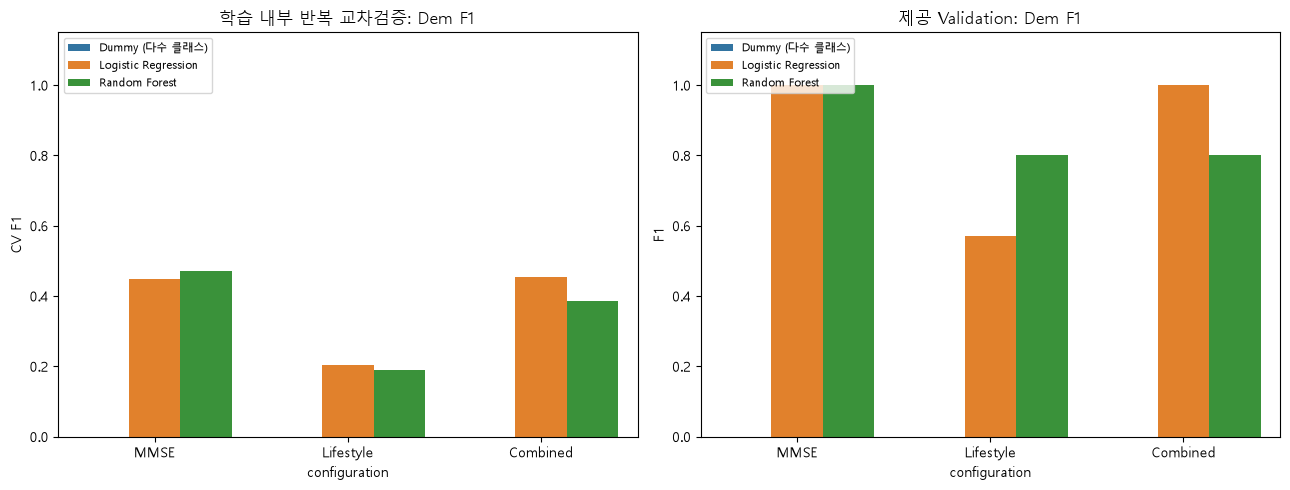

                  precision    recall  f1-score   support

not Dem (CN/MCI)       1.00      1.00      1.00        30
             Dem       1.00      1.00      1.00         3

        accuracy                           1.00        33
       macro avg       1.00      1.00      1.00        33
    weighted avg       1.00      1.00      1.00        33



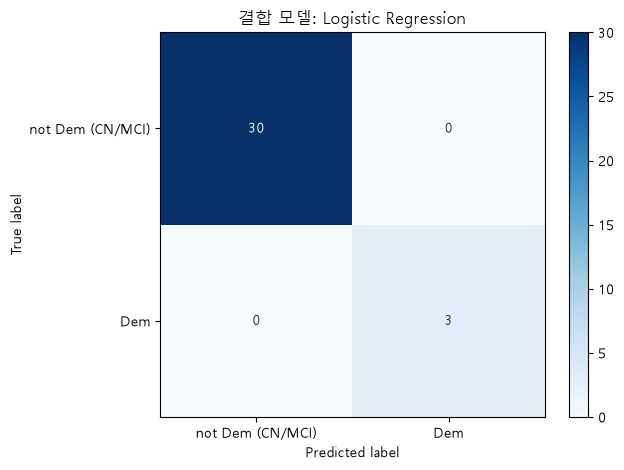

In [8]:
rows, fitted = [], {}
for kind, X in tables['train'].items():
    for name, template in models.items():
        model = clone(template).fit(X,y_train)
        pred = model.predict(tables['val'][kind])
        prob = model.predict_proba(tables['val'][kind])[:,1]
        fitted[(kind,name)] = model
        rows.append({'configuration':kind,'model':name,'accuracy':accuracy_score(y_val,pred),
          'precision':precision_score(y_val,pred,zero_division=0),'recall':recall_score(y_val,pred,zero_division=0),
          'F1':f1_score(y_val,pred,zero_division=0),'balanced accuracy':balanced_accuracy_score(y_val,pred),
          'ROC-AUC':roc_auc_score(y_val,prob)})
result_df = pd.DataFrame(rows)
display(result_df.round(3))
result_df.to_csv(OUTPUT_DIR/'model_comparison.csv',index=False,encoding='utf-8-sig')
fig,axes=plt.subplots(1,2,figsize=(13,5))
sns.barplot(data=cv_df,x='configuration',y='CV F1',hue='model',ax=axes[0],errorbar=None)
sns.barplot(data=result_df,x='configuration',y='F1',hue='model',ax=axes[1],errorbar=None)
axes[0].set_title('학습 내부 반복 교차검증: Dem F1')
axes[1].set_title('제공 Validation: Dem F1')
for ax in axes:
    ax.set_ylim(0,1.15)
    ax.legend(fontsize=8,loc='upper left')
plt.tight_layout()
plt.savefig(OUTPUT_DIR/'model_comparison.png',dpi=150,bbox_inches='tight')
plt.show()
best_model = fitted[('Combined',best_name)]
X_train, X_val = tables['train']['Combined'], tables['val']['Combined']
FEATURES = X_train.columns.tolist()
val_pred = best_model.predict(X_val)
val_prob = best_model.predict_proba(X_val)[:,1]
print(classification_report(y_val,val_pred,labels=[0,1],target_names=label_names,zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_val,val_pred,labels=[0,1],display_labels=label_names,cmap='Blues')
plt.title('결합 모델: '+best_name)
plt.tight_layout()
plt.savefig(OUTPUT_DIR/'validation_confusion_matrix.png',dpi=150,bbox_inches='tight')
plt.show()

## 5. 실제 라벨과 예측 비교
표의 대상 번호는 웹에서 사용하는 검증 대상 번호와 일치한다. 개인 식별자는 출력하지 않는다.

,person,actual,predicted,Dem_probability,correct
0,1,not Dem,not Dem,0.0044,True
1,2,not Dem,not Dem,0.0051,True
2,3,not Dem,not Dem,0.0002,True
3,4,not Dem,not Dem,0.0003,True
4,5,not Dem,not Dem,0.0171,True
5,6,not Dem,not Dem,0.0013,True
6,7,not Dem,not Dem,0.0021,True
7,8,not Dem,not Dem,0.0020,True
8,9,not Dem,not Dem,0.0001,True
9,10,not Dem,not Dem,0.0027,True


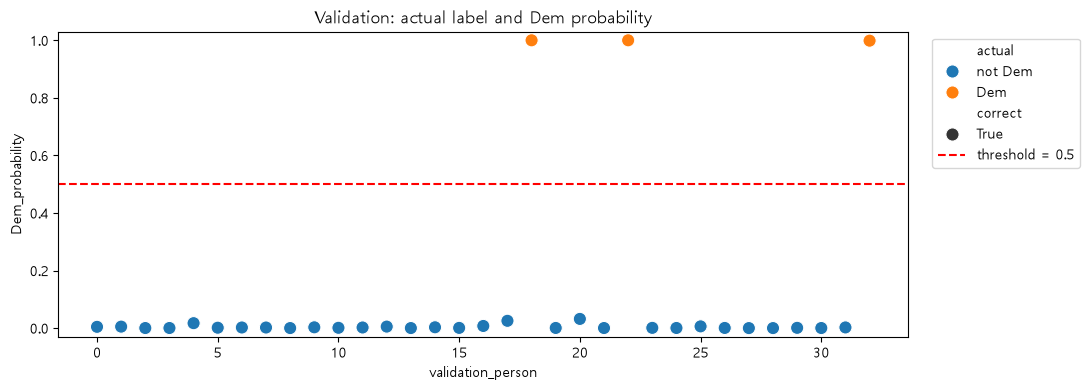

In [9]:
comparison = pd.DataFrame({
    'person': np.arange(1,len(y_val)+1),
    'actual': np.where(y_val.to_numpy() == 1, 'Dem', 'not Dem'),
    'predicted': np.where(val_pred == 1, 'Dem', 'not Dem'),
    'Dem_probability': val_prob.round(4),
    'correct': y_val.to_numpy() == val_pred
})
display(comparison)
comparison.to_csv(OUTPUT_DIR / 'validation_predictions.csv', index=False, encoding='utf-8-sig')

plot_df = comparison.reset_index(names='validation_person')
plt.figure(figsize=(11, 4))
sns.scatterplot(data=plot_df, x='validation_person', y='Dem_probability', hue='actual', style='correct', s=90)
plt.axhline(0.5, color='red', linestyle='--', label='threshold = 0.5')
plt.ylim(-0.03, 1.03)
plt.title('Validation: actual label and Dem probability')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'actual_vs_prediction.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. 결합 피쳐 중요도
기여도는 모델 설명이며 인과관계가 아니다. 중요도가 높아도 진단 근거로 해석하지 않는다.

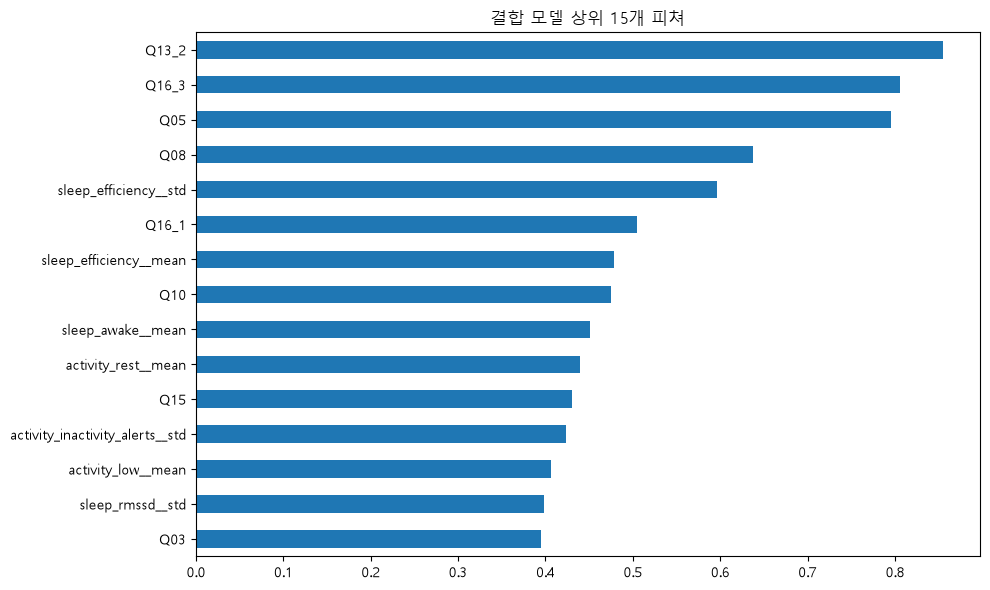

In [10]:
if best_name == 'Random Forest':
    importance = pd.Series(best_model.named_steps['model'].feature_importances_,index=FEATURES)
else:
    importance = pd.Series(abs(best_model.named_steps['model'].coef_[0]),index=FEATURES)
importance.nlargest(15).sort_values().plot.barh(figsize=(10,6))
plt.title('결합 모델 상위 15개 피쳐')
plt.tight_layout()
plt.savefig(OUTPUT_DIR/'feature_importance.png',dpi=150,bbox_inches='tight')
plt.show()

## 7. 모델 저장과 불러오기
피쳐 순서와 원천 집계 규칙을 모델과 함께 저장한다. 재로딩한 모델의 예측이 동일한지 확인한다.

In [11]:
MODEL_PATH = OUTPUT_DIR / 'combined_dem_model.joblib'
joblib.dump({'model': best_model, 'features': FEATURES, 'model_name': best_name, 'activity_columns': ACT, 'sleep_columns': SLEEP, 'aggregation': ['mean','std'], 'sklearn_version': sklearn.__version__}, MODEL_PATH)
print('저장 완료:', MODEL_PATH)
loaded = joblib.load(MODEL_PATH)
np.testing.assert_allclose(loaded['model'].predict_proba(X_val), best_model.predict_proba(X_val))
print('저장 모델 재로딩 및 예측 일치 확인 완료')

저장 완료: d:\hanyeowon\가천대학교\기계학습프로그래밍\machine-learning-programming\assignment1\라이프로그결합_output\combined_dem_model.joblib
저장 모델 재로딩 및 예측 일치 확인 완료


## 8. 저장 모델을 사용하는 웹페이지
마지막 셀의 RUN_WEB=True로 바꾸고 실행하면 출력되는 로컬 주소에서 검증 대상을 선택할 수 있다. 원천 데이터를 집계한 피쳐를 저장 모델에 입력해 예측하고 실제 라벨과 비교한다. 기본 전체 실행에서는 웹 요청과 실제 HTTP 연결을 자동 점검한 뒤 서버를 종료한다.

In [12]:
from flask import Flask, request, render_template_string
from werkzeug.serving import make_server
from threading import Thread
import urllib.request

saved = joblib.load(MODEL_PATH)
app = Flask(__name__)
HTML = """<!doctype html><html lang="ko"><meta charset="utf-8">
<title>라이프로그 치매군 분류</title><style>
body{font-family:'Malgun Gothic',sans-serif;max-width:850px;margin:48px auto;padding:20px;background:#f4f6fa;color:#1c2940}
main{background:white;padding:28px;border-radius:16px}button,select{padding:10px;margin:8px}td,th{padding:7px;border-bottom:1px solid #ddd}
</style><main><h1>MMSE·수면·활동 기반 Dem 선별 분류</h1><p>과제 시연용 · 선택 모델: {{ model_name }}</p>
<form method="post"><label>검증 대상 <select name="person">{% for i in range(count) %}<option value="{{i}}" {% if i == selected %}selected{% endif %}>대상 {{i+1}}</option>{% endfor %}</select></label><button>예측하기</button></form>
{% if result %}<h2>예측: {{result}}</h2><p>모델의 Dem 확률 추정값: {{probability}} · 실제 라벨: {{actual}} · {{correct}}</p>
<details><summary>사용한 원천 데이터에서 만든 피쳐 값</summary><table>{% for k,v in values.items() %}<tr><th>{{k}}</th><td>{{v}}</td></tr>{% endfor %}</table></details>{% endif %}
<p>검증 대상 33명 중 Dem은 3명입니다. 점수를 실제 진단 확률로 해석하지 않습니다.</p></main></html>"""

@app.route('/', methods=['GET', 'POST'])
def predict():
    selected = 0
    result = probability = actual = correct = None
    values = {}
    if request.method == 'POST':
        try:
            selected = int(request.form.get('person', ''))
            if not 0 <= selected < len(X_val):
                raise ValueError()
        except ValueError:
            return '올바른 검증 대상 번호를 선택하세요.', 400
        row = X_val.iloc[[selected]][saved['features']]
        p = float(saved['model'].predict_proba(row)[0, 1])
        prediction = int(p >= 0.5)
        result = 'Dem' if prediction else 'not Dem'
        probability = f'{p:.1%}'
        actual = 'Dem' if y_val.iloc[selected] else 'not Dem'
        correct = '정답' if prediction == y_val.iloc[selected] else '오답'
        values = row.iloc[0].to_dict()
    return render_template_string(HTML, count=len(X_val), selected=selected, result=result,
                                  probability=probability, actual=actual, correct=correct,
                                  values=values, model_name=saved['model_name'])

# 모든 검증 대상의 웹 예측 요청과 잘못된 요청을 실제 처리한다.
with app.test_client() as client:
    assert client.get('/').status_code == 200
    for i in range(len(X_val)):
        response = client.post('/', data={'person': str(i)})
        assert response.status_code == 200
        assert '예측:'.encode() in response.data
    for bad in ['', '-1', '999', 'abc']:
        assert client.post('/', data={'person': bad}).status_code == 400
print('웹 화면: GET, 검증 대상 33건 POST, 잘못된 입력 처리 통과')

if '_web_server' in globals() and _web_server is not None:
    _web_server.shutdown()
    _web_server.server_close()
    _web_server = None
RUN_WEB = True  # 웹을 열려면 True로 바꾸고 이 셀만 실행
if RUN_WEB:
    _web_server = make_server('127.0.0.1', 0, app)
    Thread(target=_web_server.serve_forever, daemon=True).start()
    print(f'웹 주소: http://127.0.0.1:{_web_server.server_port}')
else:
    # 임시 로컬 서버로 HTTP 연결까지 확인 후 종료한다.
    server = make_server('127.0.0.1', 0, app)
    worker = Thread(target=server.serve_forever, daemon=True)
    worker.start()
    try:
        with urllib.request.urlopen(f'http://127.0.0.1:{server.server_port}') as response:
            assert response.status == 200
    finally:
        server.shutdown()
        server.server_close()
        worker.join(timeout=5)
    print('로컬 HTTP 응답 확인 완료. RUN_WEB=True로 웹 시연을 시작할 수 있습니다.')

웹 화면: GET, 검증 대상 33건 POST, 잘못된 입력 처리 통과
웹 주소: http://127.0.0.1:57738


## 9. 결과와 한계
아래 문장은 실제 실행값으로 생성된다. 모든 모델의 표와 그래프를 함께 보고 생활패턴 추가 효과를 판단한다.

In [13]:
from IPython.display import Markdown
combined = result_df[(result_df.configuration=='Combined') & (result_df.model==best_name)].iloc[0]
base_cv = cv_df[(cv_df.configuration=='MMSE') & (cv_df.model==best_name)].iloc[0]
delta = float(selection['CV F1']-base_cv['CV F1'])
display(Markdown(f"""결합 모델은 **{best_name}**이며, 학습 내부 반복 CV Dem F1은 **{selection['CV F1']:.3f} ± {selection['CV F1 std']:.3f}**이다.
같은 알고리즘의 MMSE 단독 CV F1은 **{base_cv['CV F1']:.3f}**로, 결합 시 차이는 **{delta:+.3f}**이다.
제공 Validation 정확도는 **{combined['accuracy']:.1%}**, Dem 정밀도 **{combined['precision']:.3f}**, 재현율 **{combined['recall']:.3f}**, F1 **{combined['F1']:.3f}**이다.

학습은 141명(Dem 9명), 검증은 33명(Dem 3명)으로 작다. 반복되는 날짜 기록을 독립 표본으로 부풀리지 않았다.
생활패턴 피쳐 추가가 성능 향상을 보장하지 않으며, Validation 점수만으로 우월성을 결론내리지 않는다.
MMSE는 진단과 가까운 검사이므로 라벨 생성 과정과의 관계는 추가 확인이 필요하다. 수집 기간 및 기록 수 차이도 교란 요인이 될 수 있다.
이 결과는 기존 진단 라벨을 분류하는 교육용 실험이며 미래 치매 발병 예측이나 임상 성능 검증이 아니다."""))

결합 모델은 **Logistic Regression**이며, 학습 내부 반복 CV Dem F1은 **0.453 ± 0.211**이다.
같은 알고리즘의 MMSE 단독 CV F1은 **0.449**로, 결합 시 차이는 **+0.004**이다.
제공 Validation 정확도는 **100.0%**, Dem 정밀도 **1.000**, 재현율 **1.000**, F1 **1.000**이다.

학습은 141명(Dem 9명), 검증은 33명(Dem 3명)으로 작다. 반복되는 날짜 기록을 독립 표본으로 부풀리지 않았다.
생활패턴 피쳐 추가가 성능 향상을 보장하지 않으며, Validation 점수만으로 우월성을 결론내리지 않는다.
MMSE는 진단과 가까운 검사이므로 라벨 생성 과정과의 관계는 추가 확인이 필요하다. 수집 기간 및 기록 수 차이도 교란 요인이 될 수 있다.
이 결과는 기존 진단 라벨을 분류하는 교육용 실험이며 미래 치매 발병 예측이나 임상 성능 검증이 아니다.

127.0.0.1 - - [22/Sep/2026 16:29:17] "GET / HTTP/1.1" 200 -
127.0.0.1 - - [22/Sep/2026 16:29:17] "GET /favicon.ico HTTP/1.1" 404 -
127.0.0.1 - - [22/Sep/2026 16:29:19] "POST / HTTP/1.1" 200 -
